# k-nearest neighbors applied to handwritten digits (MNIST)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

MNIST is a collection of 70000 images of handwritten digits, of 28 x 28 pixels in grey scale. With k-nearest neighbors, a new image is classified as the most frequent digit among the $k$ training images closest to it, where each image is just a vector of 784 numbers and the distance is the Euclidean one.

`fetch_openml` downloads the data the first time it is called (about 15 MB, it needs internet once) and keeps a copy in the computer.

In [2]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')

images = mnist.data.reshape(-1, 28, 28)
labels = mnist.target.astype(int)

# The standard split: the first 60000 images are for training and the last 10000 for testing
train_images, test_images = images[:60000], images[60000:]
train_labels, test_labels = labels[:60000], labels[60000:]

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

kNN has to compute the distance from each new image to all the training images, so to keep the example fast we use the first 2000 training images and the first 600 testing images.

In [3]:
train_images = train_images[:2000]
train_labels = train_labels[:2000]

test_images = test_images[:600]
test_labels = test_labels[:600]

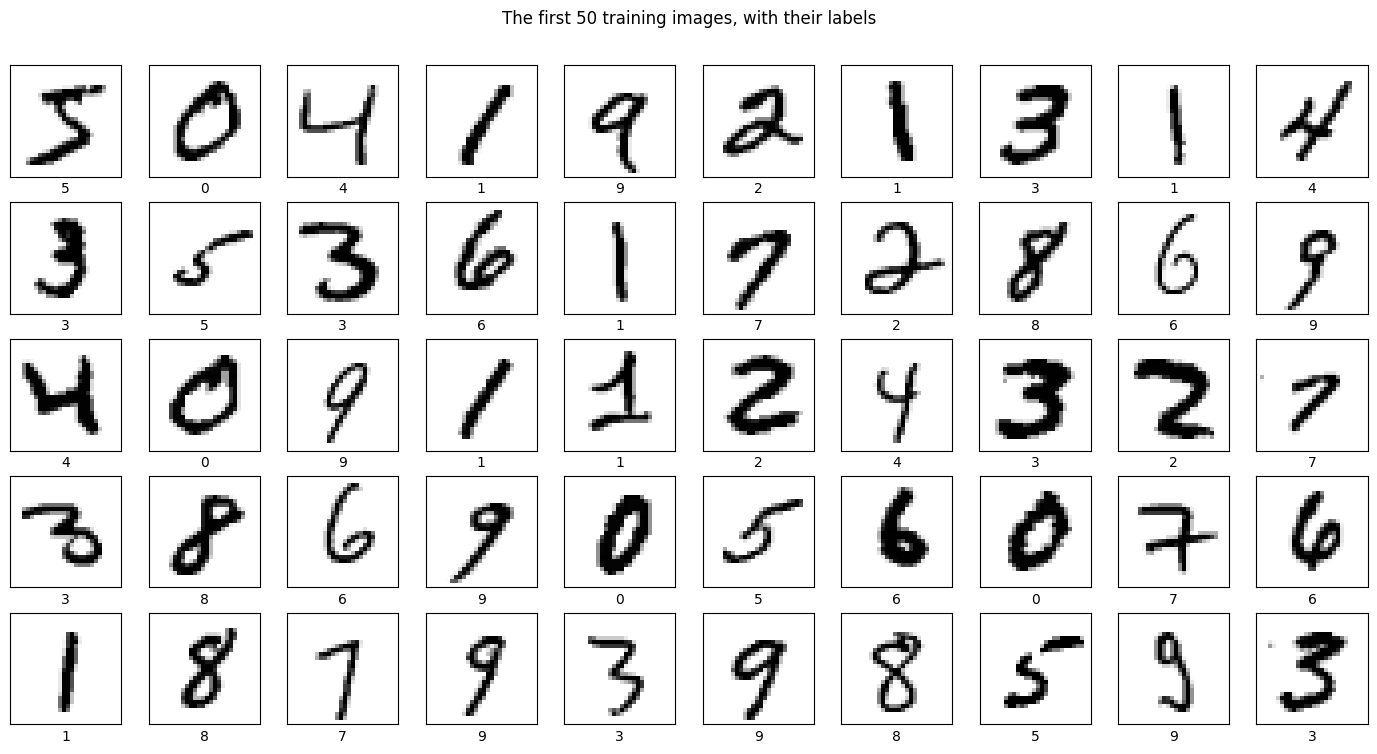

In [4]:
fig, axes = plt.subplots(5, 10, figsize=(14, 7.6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(train_images[i], cmap=plt.cm.binary)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(train_labels[i])
fig.suptitle('The first 50 training images, with their labels')
fig.tight_layout(rect=(0, 0, 1, 0.97))

In [5]:
# flattening the images
flat_train = train_images.reshape((len(train_images), np.prod(train_images.shape[1:]))).astype('float32')
flat_test = test_images.reshape((len(test_images), np.prod(test_images.shape[1:]))).astype('float32')

flat_train.shape, flat_test.shape

((2000, 784), (600, 784))

## kNN with 20 neighbors

In [6]:
knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(flat_train, train_labels)
predictions_knn = knn.predict(flat_test)

knn_cm = confusion_matrix(y_true = test_labels,
                         y_pred = predictions_knn,
                         labels = [0,1,2,3,4,5,6,7,8,9])

test_accuracy = np.diag(knn_cm).sum()/knn_cm.sum()
print(f'Testing accuracy with k = 20: {100*test_accuracy:.2f}%')

Testing accuracy with k = 20: 83.00%


### What the classifier sees

For some testing images (first column): their nearest training images. The classifier works because images of the same digit are, most of the time, close pixel by pixel. The last rows are misclassified images.

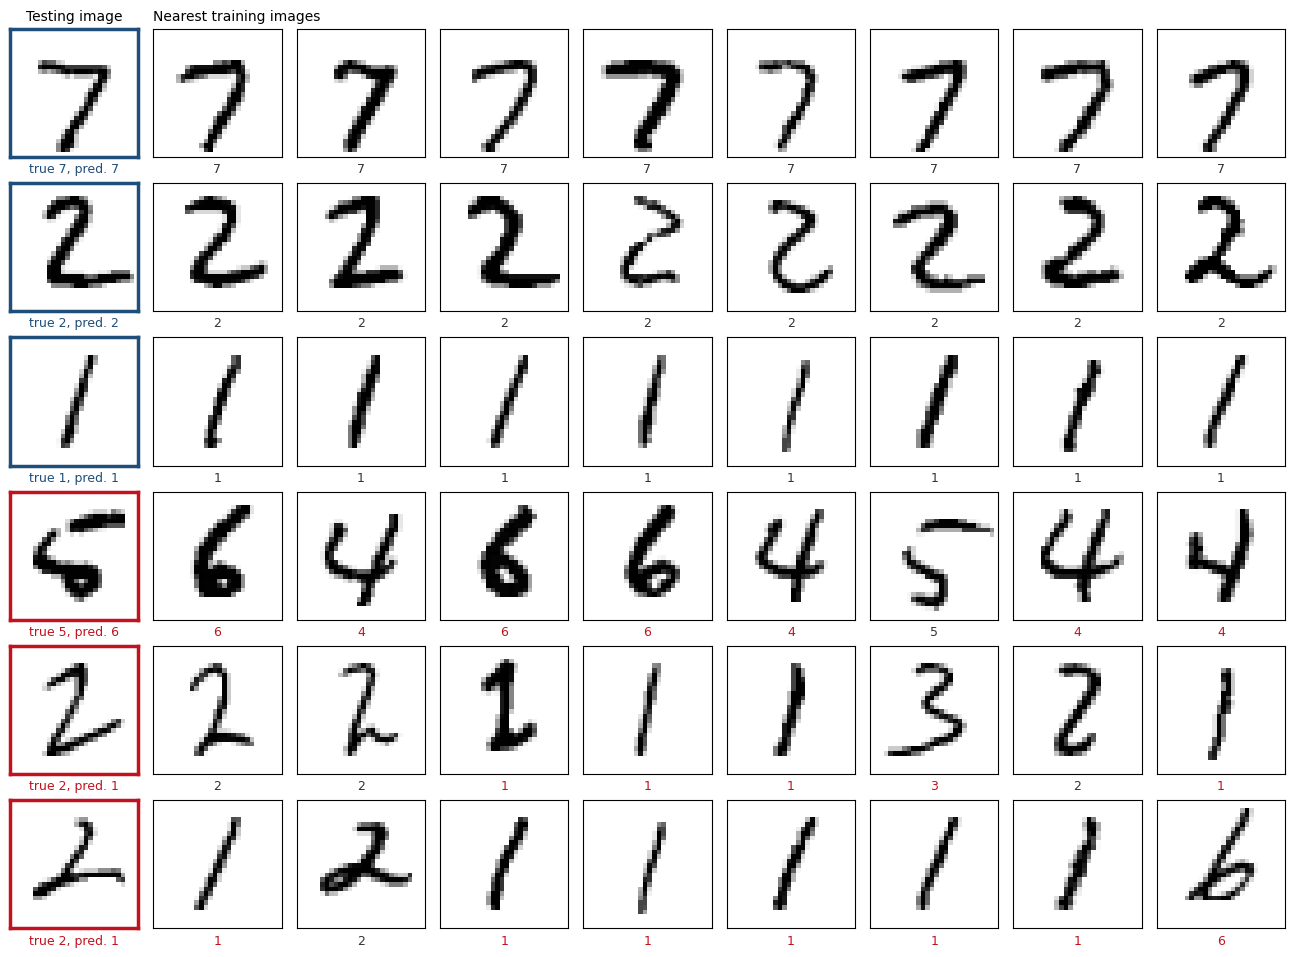

In [7]:
def plot_neighbors(indexes, n_neighbors=8):
    distances, neighbors = knn.kneighbors(flat_test[indexes], n_neighbors=n_neighbors)
    fig, axes = plt.subplots(len(indexes), n_neighbors+1, figsize=(1.45*(n_neighbors+1), 1.6*len(indexes)))
    for row, i in enumerate(indexes):
        right = predictions_knn[i] == test_labels[i]
        ax = axes[row, 0]
        ax.imshow(test_images[i], cmap=plt.cm.binary)
        ax.set_xlabel(f'true {test_labels[i]}, pred. {predictions_knn[i]}', color='#1f4e79' if right else '#c1121f',
                      fontsize=9)
        for spine in ax.spines.values():
            spine.set_edgecolor('#1f4e79' if right else '#c1121f')
            spine.set_linewidth(2.5)
        for col, j in enumerate(neighbors[row]):
            ax = axes[row, col+1]
            ax.imshow(train_images[j], cmap=plt.cm.binary)
            ax.set_xlabel(train_labels[j], fontsize=9,
                          color='#333333' if train_labels[j] == test_labels[i] else '#c1121f')
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    axes[0, 0].set_title('Testing image', fontsize=10)
    axes[0, 1].set_title('Nearest training images', fontsize=10, loc='left')
    plt.tight_layout()

right_idx = np.where(predictions_knn == test_labels)[0][:3]
wrong_idx = np.where(predictions_knn != test_labels)[0][:3]
plot_neighbors(np.r_[right_idx, wrong_idx])

### Predictions for the first testing images

Under each image: true label, predicted label (in red when they are different).

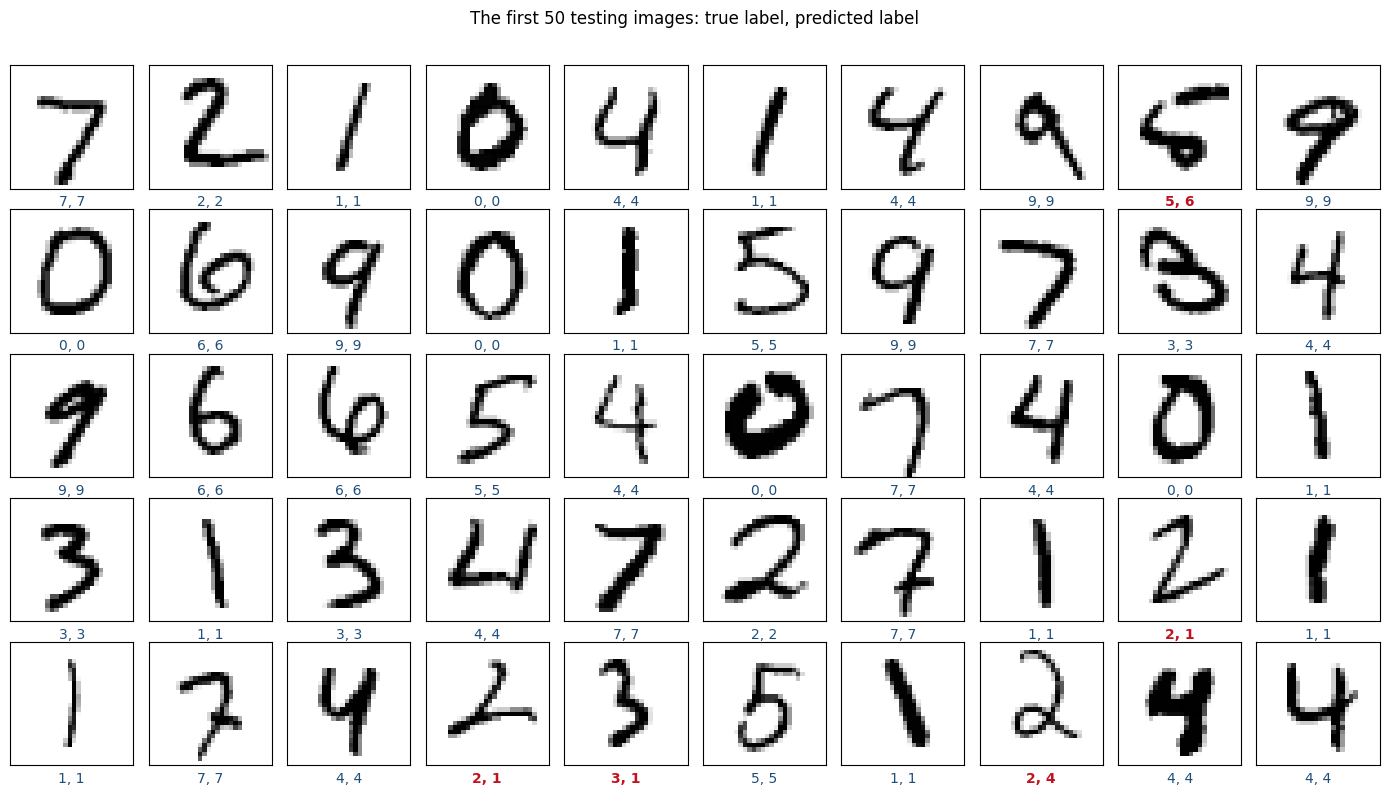

In [8]:
fig, axes = plt.subplots(5, 10, figsize=(14, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(test_images[i], cmap=plt.cm.binary)
    ax.set_xticks([])
    ax.set_yticks([])
    right = test_labels[i] == predictions_knn[i]
    ax.set_xlabel(str(test_labels[i]) + ', ' + str(predictions_knn[i]), color='#1f4e79' if right else '#c1121f',
                  fontweight='normal' if right else 'bold')
fig.suptitle('The first 50 testing images: true label, predicted label')
fig.tight_layout(rect=(0, 0, 1, 0.97))

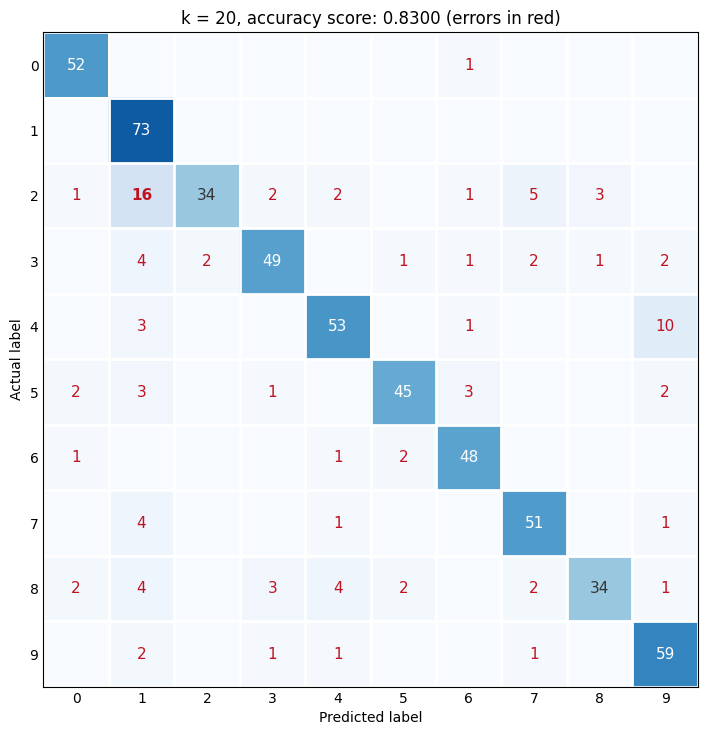

In [9]:
def plot_confusion_matrix(ax, matrix, title):
    off_diagonal = matrix - np.diag(np.diag(matrix))
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=matrix.max()*1.2)
    for i in range(10):
        for j in range(10):
            if matrix[i, j] > 0:
                ax.text(j, i, matrix[i, j], ha='center', va='center', fontsize=11,
                        color='white' if matrix[i, j] > 0.6*matrix.max() else ('#c1121f' if i != j else '#333333'),
                        fontweight='bold' if i != j and matrix[i, j] == off_diagonal.max() else 'normal')
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xticks(np.arange(11)-0.5, minor=True)
    ax.set_yticks(np.arange(11)-0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='both', length=0)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(9, 8.5))
plot_confusion_matrix(ax, knn_cm, f'k = 20, accuracy score: {test_accuracy:.4f} (errors in red)')

## Choosing k

We choose $k$ with 5-fold cross-validation in the training images. The testing images are not used to choose $k$: if they were, the testing accuracy of the chosen model would be optimistic. For comparison, we also compute the testing accuracy for each $k$.

In [10]:
k_range = range(1, 31)
k_scores = []
k_test_scores = []
# use iteration to calculate different k in models, then return the average accuracy based on the cross validation
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    k_scores.append(cross_val_score(knn, flat_train, train_labels, cv=5).mean())
    k_test_scores.append(knn.fit(flat_train, train_labels).score(flat_test, test_labels))

k_star = np.where(k_scores == max(k_scores))[0][0]+1
print('k_star:', k_star)

k_star: 1


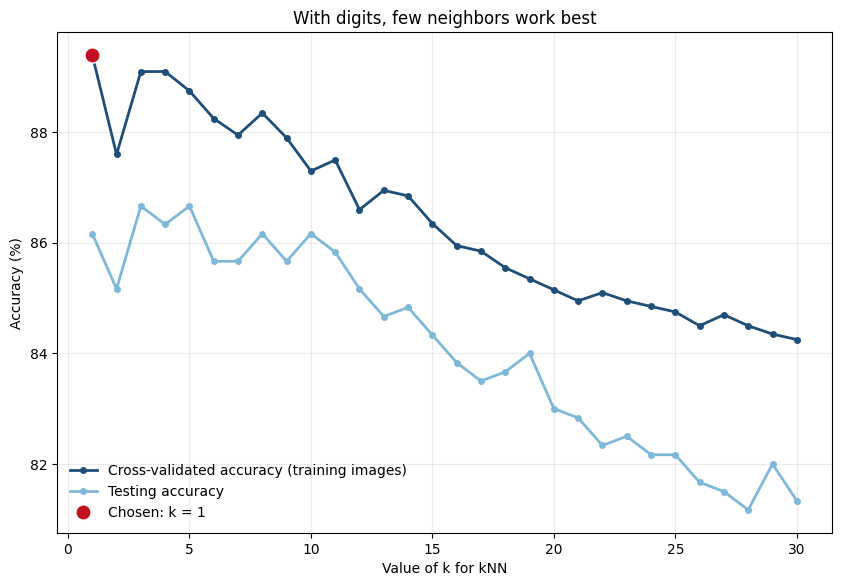

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(k_range, 100*np.array(k_scores), 'o-', color='#1f4e79', lw=2, markersize=4,
        label='Cross-validated accuracy (training images)')
ax.plot(k_range, 100*np.array(k_test_scores), 'o-', color='#7fb8d8', lw=2, markersize=4, label='Testing accuracy')
ax.plot(k_star, 100*max(k_scores), 'o', color='#c1121f', markersize=11, markeredgecolor='white', markeredgewidth=1,
        label=f'Chosen: k = {k_star}')
ax.set_xlabel('Value of k for kNN')
ax.set_ylabel('Accuracy (%)')
ax.set_title('With digits, few neighbors work best')
ax.legend(loc='lower left', frameon=False)
ax.grid(True, alpha=0.25)

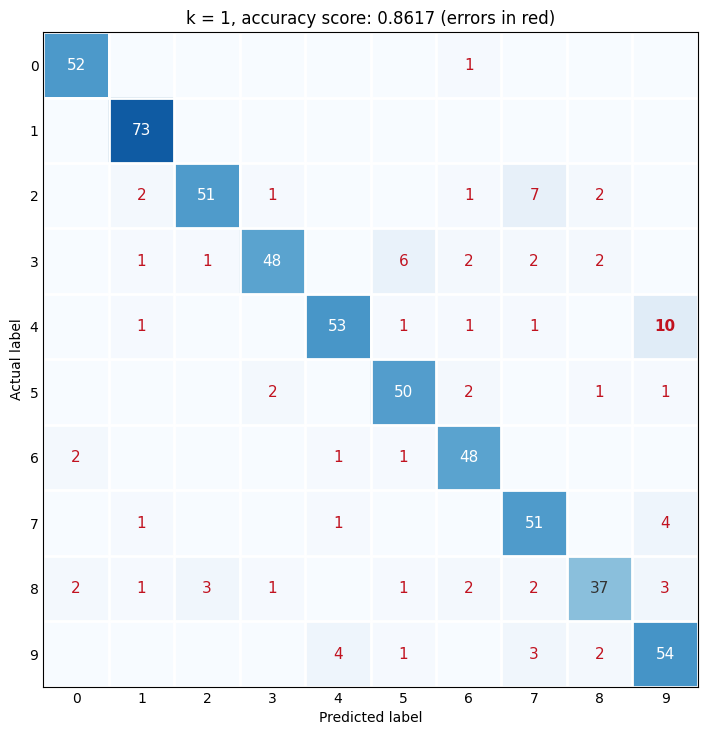

In [12]:
knn = KNeighborsClassifier(n_neighbors=k_star)
knn.fit(flat_train, train_labels)
predictions_knn = knn.predict(flat_test)

knn_cm = confusion_matrix(y_true = test_labels,
                         y_pred = predictions_knn,
                         labels = [0,1,2,3,4,5,6,7,8,9])

test_accuracy = np.diag(knn_cm).sum()/knn_cm.sum()

fig, ax = plt.subplots(figsize=(9, 8.5))
plot_confusion_matrix(ax, knn_cm, f'k = {k_star}, accuracy score: {test_accuracy:.4f} (errors in red)')

### The misclassified images

Some of the errors are digits that a person would also doubt about; others are clear for us but, pixel by pixel, closer to images of another digit.

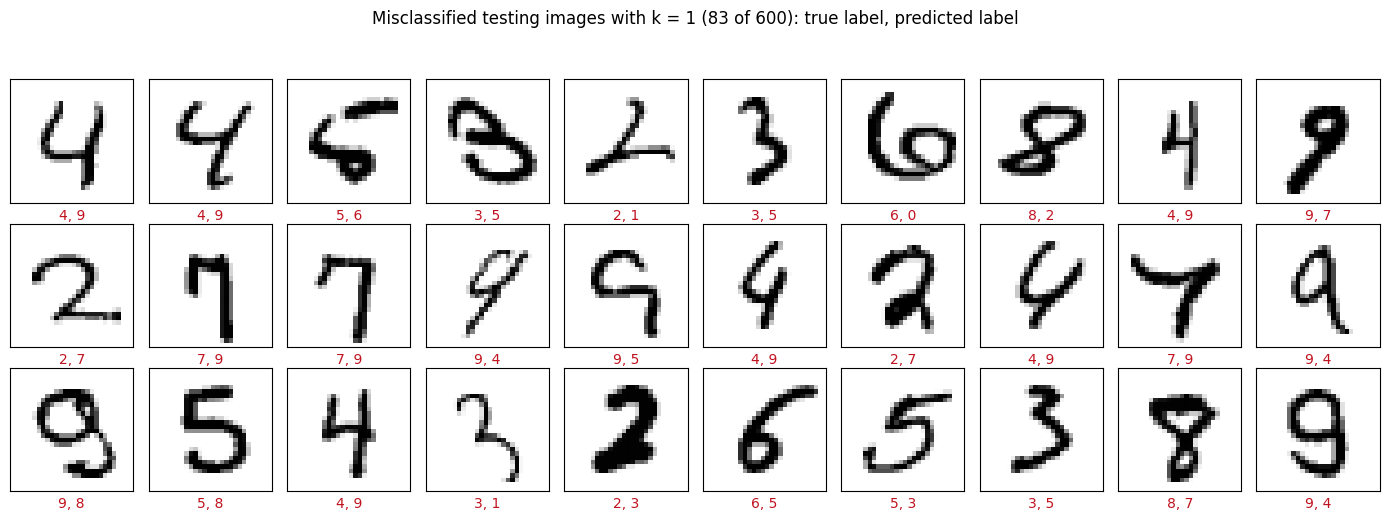

In [13]:
wrong_idx = np.where(predictions_knn != test_labels)[0]
n_show = min(len(wrong_idx), 30)

fig, axes = plt.subplots(3, 10, figsize=(14, 5.2))
for ax in axes.ravel():
    ax.set_axis_off()
for ax, i in zip(axes.ravel(), wrong_idx[:n_show]):
    ax.set_axis_on()
    ax.imshow(test_images[i], cmap=plt.cm.binary)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f'{test_labels[i]}, {predictions_knn[i]}', color='#c1121f')
fig.suptitle(f'Misclassified testing images with k = {k_star} ({len(wrong_idx)} of {len(test_labels)}): true label, predicted label')
fig.tight_layout(rect=(0, 0, 1, 0.95))